# 1. Markowitz optimisation and its weak point

Markowitz (1952): among all portfolios with a given expected return, choose the one with the smallest variance. With weights $w$, expected returns $\mu$ and covariance matrix $\Sigma$:

$$\min_w\ w^\top \Sigma\, w \quad \text{subject to} \quad w^\top\mu = m,\ \ \sum_i w_i = 1 .$$

The theory is exact. The difficulty is that $\mu$ and $\Sigma$ are not known: they are estimated from past returns, and the optimiser is extremely sensitive to estimation errors. This notebook shows the problem; the next two deal with the covariance part of it.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `portfolio` package importable from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio import covariance as cov
from portfolio import load_prices, metrics, optimizer, rmt, run_backtest, sector_of, simulate_returns, split_benchmark, to_returns
from portfolio.backtest import equal_weight_strategy, max_sharpe_strategy, min_variance_strategy, risk_parity_strategy
from portfolio.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT, GRID

use_style()
pd.options.display.float_format = "{:.3f}".format

returns, benchmark = split_benchmark(to_returns(load_prices("../data/prices.csv")))
sectors = sector_of(returns.columns)
COLORS = {"Sample": ORANGE, "Ledoit-Wolf": AQUA, "RMT clipping": BLUE, "Equal weight": MUTED}
print(f"{returns.shape[1]} stocks, {len(returns):,} trading days, {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")

104 stocks, 4,242 trading days, 2010-01-05 to 2026-11-13


## 1.1 The efficient frontier

Estimating $\mu$ and $\Sigma$ on two years of data and solving for a range of target returns gives the efficient frontier (long-only here).

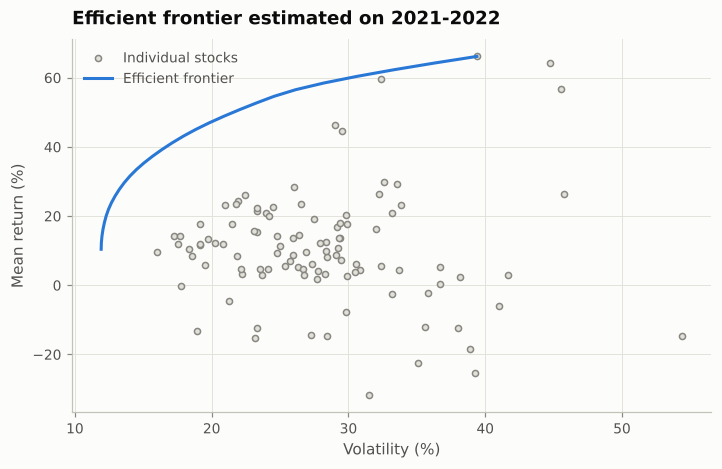

In [2]:
train = returns.loc["2021":"2022"]
test = returns.loc["2023":"2024"]
mu, sigma = train.mean().to_numpy(), cov.sample_covariance(train)

frontier_vol, frontier_ret, frontier_weights = optimizer.efficient_frontier(mu, sigma, n_points=30)
annual = 252
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(100 * np.sqrt(annual * np.diag(sigma)), 100 * annual * mu, linestyle="none", marker="o", markersize=4,
        color=GRID, markeredgecolor=MUTED, label="Individual stocks")
ax.plot(100 * np.sqrt(annual) * frontier_vol, 100 * annual * frontier_ret, color=BLUE, label="Efficient frontier")
ax.set_xlabel("Volatility (%)"); ax.set_ylabel("Mean return (%)")
ax.set_title("Efficient frontier estimated on 2021-2022"); ax.legend();

## 1.2 What happens next

The frontier was built from 2021-2022. Holding the same portfolios over 2023-2024 shows what an investor would actually have got.

,Predicted return,Realised return,Predicted vol,Realised vol
Minimum variance,0.104,0.057,0.119,0.100
Frontier point 11,0.296,0.061,0.136,0.106
Frontier point 21,0.489,0.151,0.209,0.152
Maximum return,0.662,-0.022,0.394,0.259


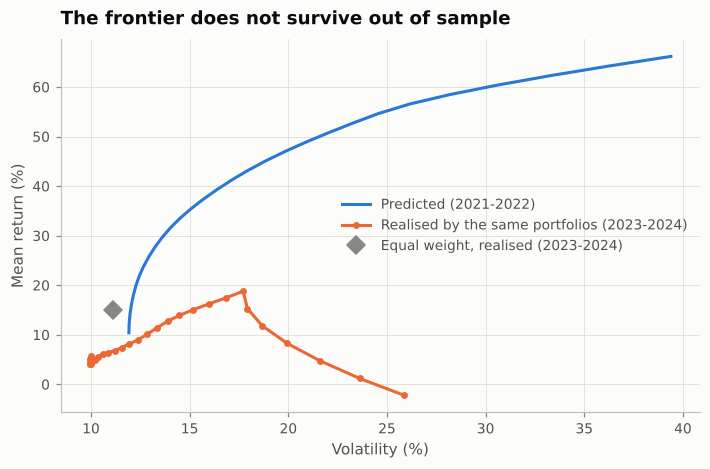

In [3]:
test_mu, test_sigma = test.mean().to_numpy(), cov.sample_covariance(test)
realised_vol = np.sqrt(annual * np.einsum("ij,jk,ik->i", frontier_weights, test_sigma, frontier_weights))
realised_ret = annual * frontier_weights @ test_mu

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(100 * np.sqrt(annual) * frontier_vol, 100 * annual * frontier_ret, color=BLUE, label="Predicted (2021-2022)")
ax.plot(100 * realised_vol, 100 * realised_ret, color=ORANGE, marker="o", markersize=3.5, label="Realised by the same portfolios (2023-2024)")
equal = np.full(len(mu), 1 / len(mu))
ax.plot(100 * np.sqrt(annual * equal @ test_sigma @ equal), 100 * annual * equal @ test_mu, linestyle="none", marker="D",
        markersize=8, color=MUTED, label="Equal weight, realised (2023-2024)")
ax.set_xlabel("Volatility (%)"); ax.set_ylabel("Mean return (%)")
ax.set_title("The frontier does not survive out of sample"); ax.legend();

summary = pd.DataFrame({"Predicted return": annual * frontier_ret, "Realised return": realised_ret,
                        "Predicted vol": np.sqrt(annual) * frontier_vol, "Realised vol": realised_vol}).iloc[[0, 10, 20, 29]]
summary.index = ["Minimum variance", "Frontier point 11", "Frontier point 21", "Maximum return"]
summary

## 1.3 Why: the optimiser maximises the estimation error

The optimiser looks for stocks with high estimated returns and low estimated risk. Among a hundred noisy estimates, the most extreme ones are mostly extreme *because* of noise, and those are exactly the ones selected. Two consequences can be measured directly.

**Expected returns are barely estimable.** The standard error of a mean annual return estimated over $T$ years is $\sigma/\sqrt{T}$:

In [4]:
vol = float(np.sqrt(annual) * returns.std().median())
pd.DataFrame({"Years of data": [1, 2, 5, 10, 17, 50],
              "Standard error of the mean return": [vol / np.sqrt(t) for t in [1, 2, 5, 10, 17, 50]]}).set_index("Years of data").style.format("{:.1%}")

,Standard error of the mean return
Years of data,
1,26.2%
2,18.6%
5,11.7%
10,8.3%
17,6.4%
50,3.7%


In [5]:
print(f"Median stock volatility: {vol:.1%}")
rank_correlation = pd.Series(mu).corr(pd.Series(test_mu), method="spearman")
print(f"Rank correlation between mean returns in 2021-2022 and in 2023-2024: {rank_correlation:.2f}")
vol_correlation = pd.Series(np.diag(sigma)).corr(pd.Series(np.diag(test_sigma)), method="spearman")
print(f"Rank correlation between variances over the same two periods: {vol_correlation:.2f}")

Median stock volatility: 26.2%


Rank correlation between mean returns in 2021-2022 and in 2023-2024: -0.23
Rank correlation between variances over the same two periods: 0.74


Past mean returns say almost nothing about future ones, while volatilities are persistent. This is why the rest of the project concentrates on the **minimum-variance** portfolio, which needs no expected returns: it isolates the effect of the covariance estimate.

**Weights are unstable.** Re-estimating the maximum-Sharpe portfolio one year later, on a window that shares half of its data with the previous one, replaces most of the portfolio:

In [6]:
periods = {"2019-2020": returns.loc["2019":"2020"], "2020-2021": returns.loc["2020":"2021"],
           "2021-2022": returns.loc["2021":"2022"], "2022-2023": returns.loc["2022":"2023"]}
weights = pd.DataFrame({name: optimizer.max_sharpe(data.mean().to_numpy(), cov.sample_covariance(data))
                        for name, data in periods.items()}, index=returns.columns)
held = weights[(weights > 0.01).any(axis=1)]
overlap = pd.DataFrame({"Stocks held": (weights > 0.001).sum(),
                        "Largest weight": weights.max(),
                        "Weight kept from the previous period": [np.nan] + [np.minimum(weights.iloc[:, i], weights.iloc[:, i - 1]).sum()
                                                                            for i in range(1, weights.shape[1])]})
display(overlap)
held.sort_values("2021-2022", ascending=False).head(12).style.format("{:.1%}")

,Stocks held,Largest weight,Weight kept from the previous period
2019-2020,8,0.298,NaN
2020-2021,12,0.292,0.236
2021-2022,9,0.295,0.129
2022-2023,10,0.331,0.462


,2019-2020,2020-2021,2021-2022,2022-2023
XOM,0.0%,0.0%,29.5%,18.5%
LLY,0.0%,12.9%,23.8%,33.1%
GIS,5.2%,0.0%,22.6%,0.0%
GILD,0.0%,0.0%,12.6%,0.0%
COP,0.0%,0.0%,5.6%,0.0%
MRK,0.0%,0.0%,3.5%,19.5%
CI,0.0%,0.0%,1.6%,0.0%
LMT,0.0%,0.0%,0.4%,4.1%
PFE,0.0%,2.3%,0.1%,0.0%
COST,0.0%,29.2%,0.0%,0.0%


## 1.4 Black-Litterman: a way to use views without extreme weights

Black and Litterman (1992) start from the returns that would make a reference portfolio optimal (reverse optimisation, $\pi = \lambda\,\Sigma\,w_{\text{ref}}$) and move them only as far as the investor's views justify. Market capitalisations are not in the data set, so the equal-weight portfolio is used as the reference here.

View: *technology will outperform utilities by 3% a year more than the reference implies*.

In [7]:
recent = returns.iloc[-504:]
sigma_clean = cov.rmt_clipped(recent)
n = recent.shape[1]
reference = optimizer.equal_weight(n)
equilibrium = optimizer.black_litterman(sigma_clean, reference)

tech = (sectors == "Technology").to_numpy()
utilities = (sectors == "Utilities").to_numpy()
view = tech / tech.sum() - utilities / utilities.sum()
target = view @ equilibrium + 0.03 / 252
posterior = optimizer.black_litterman(sigma_clean, reference, views_matrix=view, views=[target])

bl_weights = pd.Series(optimizer.mean_variance(posterior, sigma_clean, 2.5, long_only=False), index=recent.columns)
naive_weights = pd.Series(optimizer.mean_variance(recent.mean().to_numpy(), sigma_clean, 2.5, long_only=False), index=recent.columns)

by_sector = pd.DataFrame({"Reference (equal weight)": pd.Series(reference, index=recent.columns).groupby(sectors).sum(),
                          "Black-Litterman with the view": bl_weights.groupby(sectors).sum(),
                          "Markowitz with historical means": naive_weights.groupby(sectors).sum()})
print(f"Implied outperformance of tech over utilities: reference {252 * view @ equilibrium:.1%}, "
      f"view {252 * target:.1%}, posterior {252 * view @ posterior:.1%}")
print(f"Largest absolute stock weight: Black-Litterman {bl_weights.abs().max():.1%}, "
      f"historical means {naive_weights.abs().max():.1%}")
by_sector.style.format("{:.1%}")

Implied outperformance of tech over utilities: reference 3.0%, view 6.0%, posterior 4.5%
Largest absolute stock weight: Black-Litterman 1.5%, historical means 403.1%


,Reference (equal weight),Black-Litterman with the view,Markowitz with historical means
sector,,,
Communication,5.8%,5.8%,-64.7%
Consumer Discretionary,9.6%,9.6%,-430.5%
Consumer Staples,10.6%,10.6%,193.2%
Energy,4.8%,4.8%,-91.2%
Financials,14.4%,14.4%,116.9%
Health Care,15.4%,15.4%,57.8%
Industrials,15.4%,15.4%,313.1%
Materials,3.8%,3.8%,-15.9%
Real Estate,2.9%,2.9%,55.0%


## Summary

* The efficient frontier computed from past data is not what the same portfolios deliver afterwards.
* Mean returns cannot be estimated with useful precision from a few years of data, and the optimiser amplifies their errors; volatilities are far more stable.
* Black-Litterman turns a view into a moderate, interpretable tilt instead of an extreme portfolio.
* The remaining notebooks study the covariance matrix alone, through the minimum-variance portfolio.